In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
%pip install matplotlib scikit-learn seaborn pandas scipy imbalanced-learn


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python3.12 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
# ----- CELL 1 : STEP 1 - IMPORT PACKAGES -----
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

In [4]:

# ----- CELL 2 : STEP 2 - LOAD THE DATA -----
df = pd.read_csv('credit_default_data.csv')
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (2525, 15)


,Customer_ID,Age,Annual_Income_USD,Employment_Years,Credit_Score,Loan_Amount_USD,Loan_Term_Months,Interest_Rate_Pct,Debt_to_Income_Ratio,Num_Late_Payments_12M,Employment_Type,Education,Home_Ownership,Loan_Purpose,Default
0,CUST100325,42,56197.0,4.9,545.0,43062,24,9.91,0.428,2,Salaried,High School,Mortgage,Personal,1
1,CUST101753,30,84263.0,1.9,641.0,34586,60,11.26,0.192,0,Salaried,Graduate,Rent,Business,0
2,CUST101398,40,106258.0,6.7,645.0,44464,48,11.77,0.241,1,Self-Employed,Graduate,Mortgage,Personal,0
3,CUST100026,34,35757.0,1.4,474.0,10213,24,11.23,0.272,1,Salaried,Post Graduate,Own,Home Improvement,0
4,CUST101453,26,47432.0,1.0,575.0,12276,24,11.87,0.068,1,Salaried,High School,Mortgage,Education,0


In [5]:

# ----- CELL 3 : STEP 3a - DUPLICATES -----
print("Duplicate rows found:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", df.shape[0])

Duplicate rows found: 25
Rows after removing duplicates: 2500


In [6]:
# ----- CELL 4 : STEP 3b - MISSING VALUES -----
print(df.isnull().sum())


Customer_ID               0
Age                       0
Annual_Income_USD        35
Employment_Years         45
Credit_Score             55
Loan_Amount_USD           0
Loan_Term_Months          0
Interest_Rate_Pct         0
Debt_to_Income_Ratio      0
Num_Late_Payments_12M     0
Employment_Type           0
Education                 0
Home_Ownership           30
Loan_Purpose              0
Default                   0
dtype: int64


In [7]:

df['Credit_Score']       = df['Credit_Score'].fillna(df['Credit_Score'].median())
df['Employment_Years']   = df['Employment_Years'].fillna(df['Employment_Years'].median())
df['Annual_Income_USD']  = df['Annual_Income_USD'].fillna(df['Annual_Income_USD'].median())
df['Home_Ownership']     = df['Home_Ownership'].fillna(df['Home_Ownership'].mode()[0])

print("\nMissing values remaining:", df.isnull().sum().sum())


Missing values remaining: 0


In [8]:
# ----- CELL 5 : STEP 3c - DROP THE IDENTIFIER COLUMN -----
df = df.drop(columns=['Customer_ID'])
print("Columns now:", list(df.columns))

Columns now: ['Age', 'Annual_Income_USD', 'Employment_Years', 'Credit_Score', 'Loan_Amount_USD', 'Loan_Term_Months', 'Interest_Rate_Pct', 'Debt_to_Income_Ratio', 'Num_Late_Payments_12M', 'Employment_Type', 'Education', 'Home_Ownership', 'Loan_Purpose', 'Default']


In [9]:
# ----- CELL 6 : STEP 4a - SHAPE, DATA TYPES, DESCRIPTIVE SUMMARY -----
print("Shape:", df.shape)
print()
print(df.dtypes)
print()
df.describe()

Shape: (2500, 14)

Age                        int64
Annual_Income_USD        float64
Employment_Years         float64
Credit_Score             float64
Loan_Amount_USD            int64
Loan_Term_Months           int64
Interest_Rate_Pct        float64
Debt_to_Income_Ratio     float64
Num_Late_Payments_12M      int64
Employment_Type              str
Education                    str
Home_Ownership               str
Loan_Purpose                 str
Default                    int64
dtype: object



,Age,Annual_Income_USD,Employment_Years,Credit_Score,Loan_Amount_USD,Loan_Term_Months,Interest_Rate_Pct,Debt_to_Income_Ratio,Num_Late_Payments_12M,Default
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000
mean,42.728800,62029.849200,7.614320,658.841600,31827.724400,37.28640,11.208208,0.280287,0.749200,0.163200
std,12.753898,27076.907008,5.436291,93.945463,21865.234319,14.25665,1.392563,0.121934,0.925333,0.369622
min,21.000000,18000.000000,-0.000000,352.000000,2000.000000,12.00000,6.180000,0.030000,0.000000,0.000000
25%,32.000000,43170.250000,3.300000,595.000000,15091.250000,24.00000,10.250000,0.186000,0.000000,0.000000
50%,42.000000,56913.000000,6.600000,661.000000,27348.500000,36.00000,11.180000,0.280000,1.000000,0.000000
75%,54.000000,74569.500000,11.000000,723.000000,43589.250000,48.00000,12.160000,0.372000,1.000000,0.000000
max,65.000000,237974.000000,26.000000,850.000000,170389.000000,60.00000,16.130000,0.653000,6.000000,1.000000


Default
0    2092
1     408
Name: count, dtype: int64

Default
0    83.68
1    16.32
Name: proportion, dtype: float64


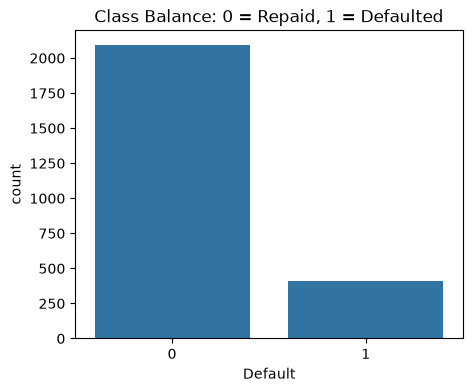

In [10]:
# ----- CELL 7 : STEP 4b - TARGET CLASS BALANCE -----
print(df['Default'].value_counts())
print()
print(df['Default'].value_counts(normalize=True).round(4) * 100)

plt.figure(figsize=(5, 4))
sns.countplot(x='Default', data=df)
plt.title('Class Balance: 0 = Repaid, 1 = Defaulted')
plt.show()

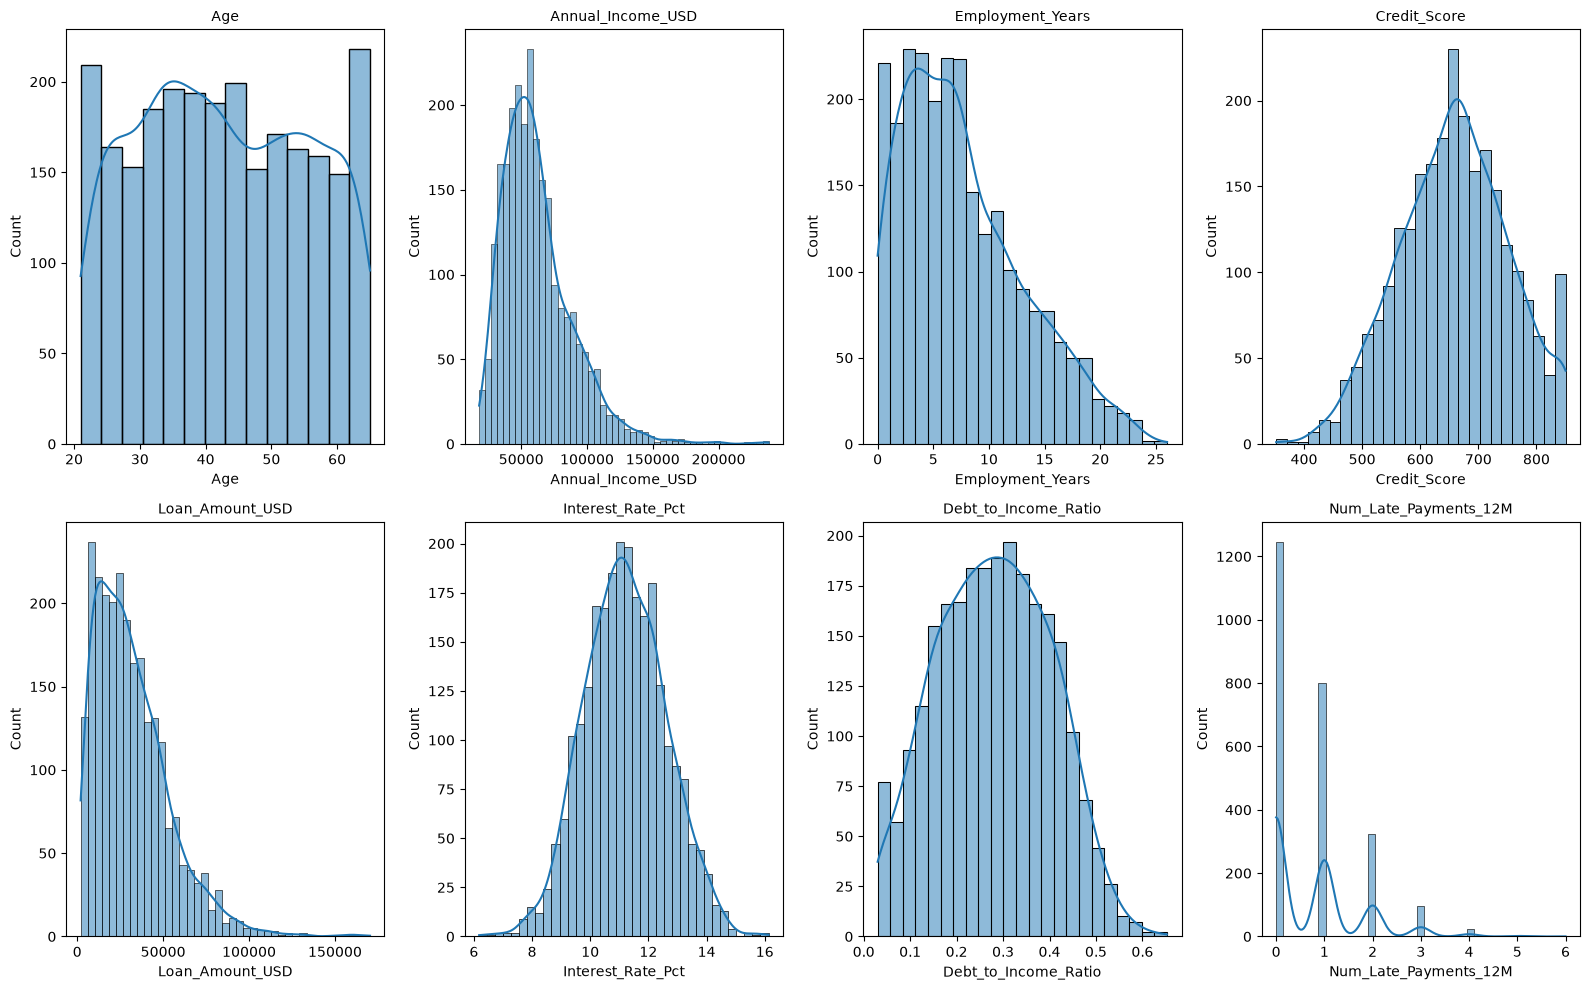

In [11]:

# ----- CELL 8 : STEP 4c - UNIVARIATE: HISTOGRAMS WITH KDE -----
numeric_cols = ['Age', 'Annual_Income_USD', 'Employment_Years', 'Credit_Score',
                'Loan_Amount_USD', 'Interest_Rate_Pct', 'Debt_to_Income_Ratio',
                'Num_Late_Payments_12M']

plt.figure(figsize=(16, 10))
for i, col in enumerate(numeric_cols):
    plt.subplot(2, 4, i+1)
    sns.histplot(data=df, x=col, kde=True)
    plt.title(col, fontsize=10)
plt.tight_layout()
plt.show()


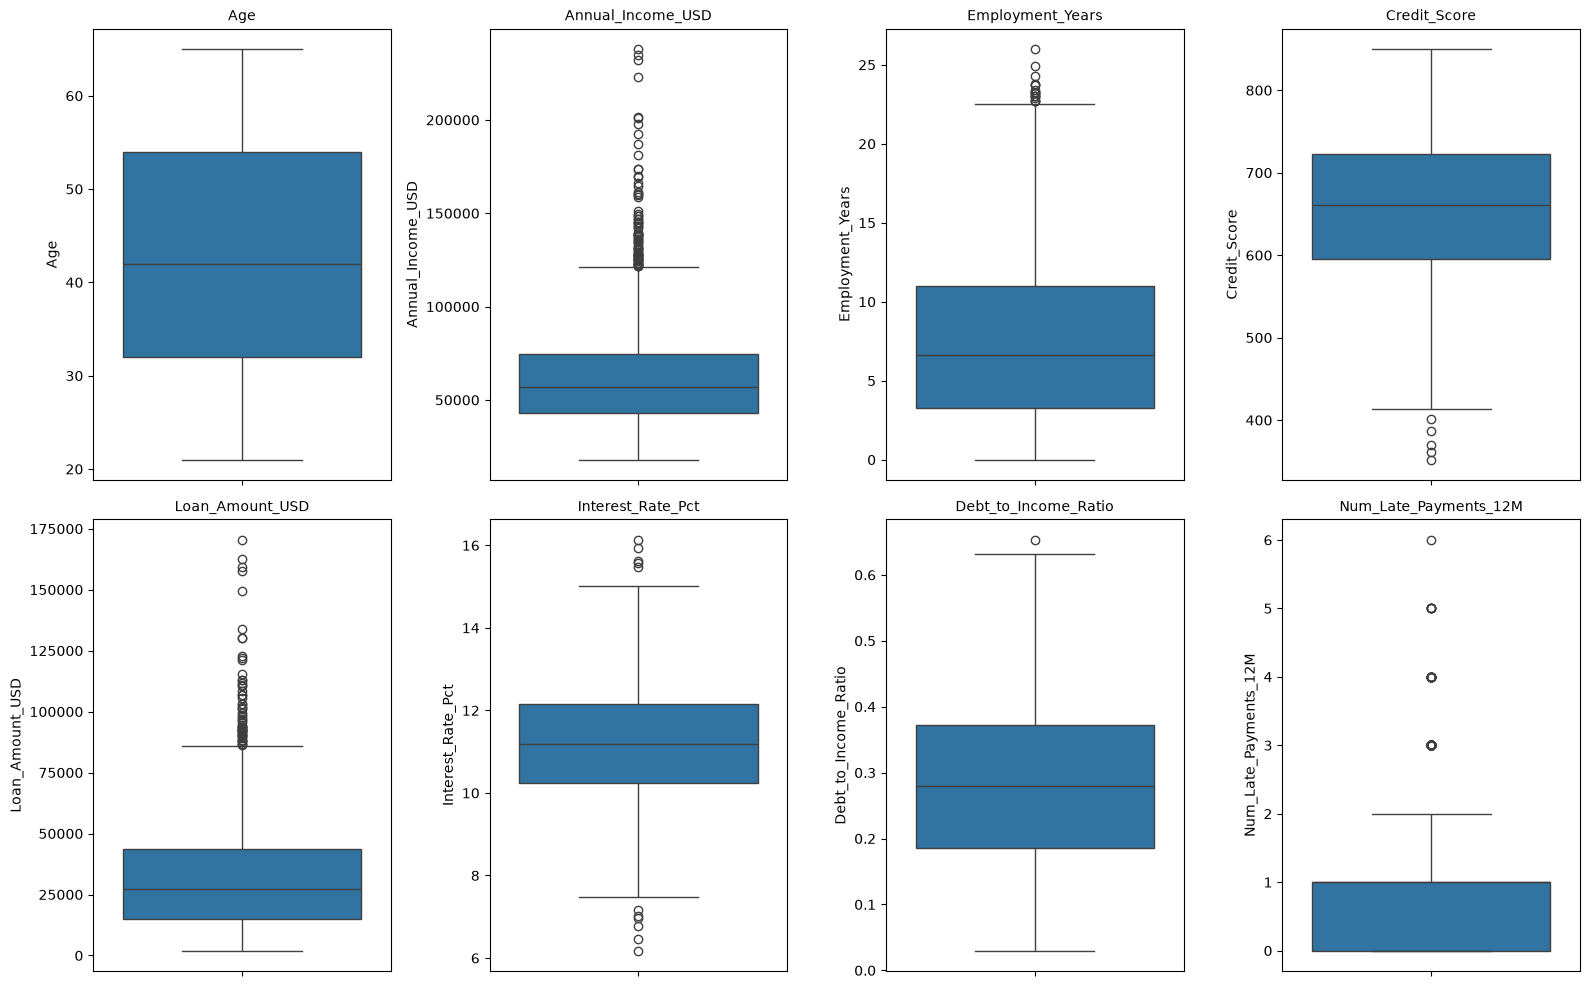

In [12]:
# ----- CELL 9 : STEP 4d - UNIVARIATE: BOXPLOTS FOR OUTLIERS -----
plt.figure(figsize=(16, 10))
for i, col in enumerate(numeric_cols):
    plt.subplot(2, 4, i+1)
    sns.boxplot(y=df[col])
    plt.title(col, fontsize=10)
plt.tight_layout()
plt.show()

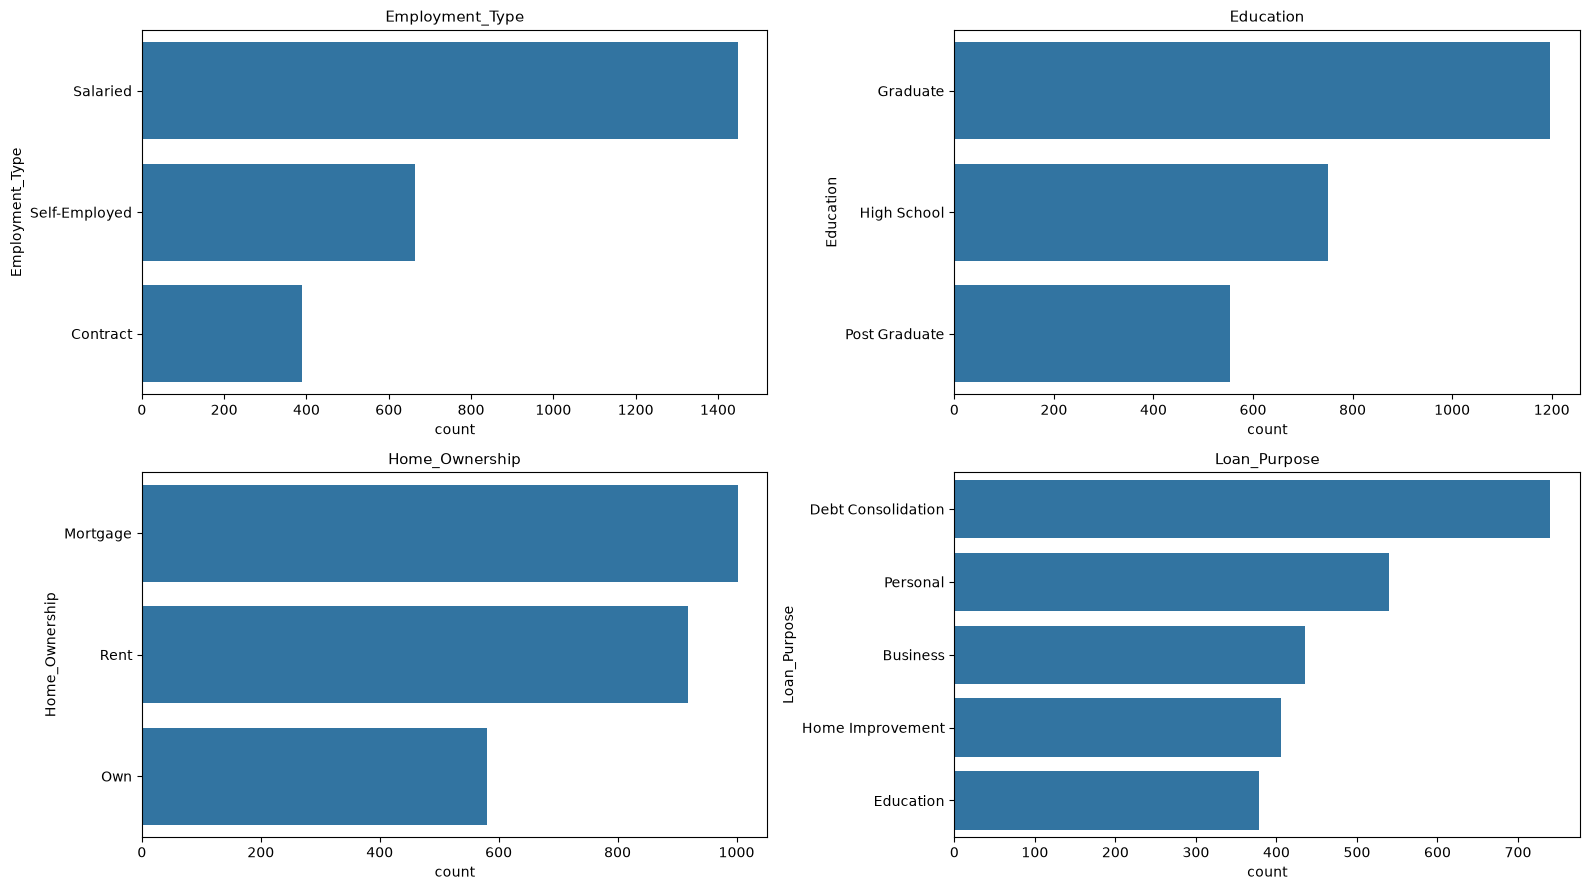

In [13]:

# ----- CELL 10 : STEP 4e - UNIVARIATE: CATEGORICAL BAR CHARTS -----
categorical_cols = ['Employment_Type', 'Education', 'Home_Ownership', 'Loan_Purpose']

plt.figure(figsize=(16, 9))
for i, col in enumerate(categorical_cols):
    plt.subplot(2, 2, i+1)
    sns.countplot(y=col, data=df, order=df[col].value_counts().index)
    plt.title(col, fontsize=11)
plt.tight_layout()
plt.show()

Shapiro-Wilk test   (H0: the variable is normally distributed)
--------------------------------------------------------------
Age                      W=0.9569  p=1.34e-26  -> NOT normal
Annual_Income_USD        W=0.9071  p=1.42e-36  -> NOT normal
Employment_Years         W=0.9444  p=1.03e-29  -> NOT normal
Credit_Score             W=0.9936  p=5.15e-09  -> NOT normal
Loan_Amount_USD          W=0.9054  p=7.73e-37  -> NOT normal
Interest_Rate_Pct        W=0.9991  p=0.249  -> Normal
Debt_to_Income_Ratio     W=0.9902  p=5.14e-12  -> NOT normal
Num_Late_Payments_12M    W=0.7661  p=8.39e-51  -> NOT normal


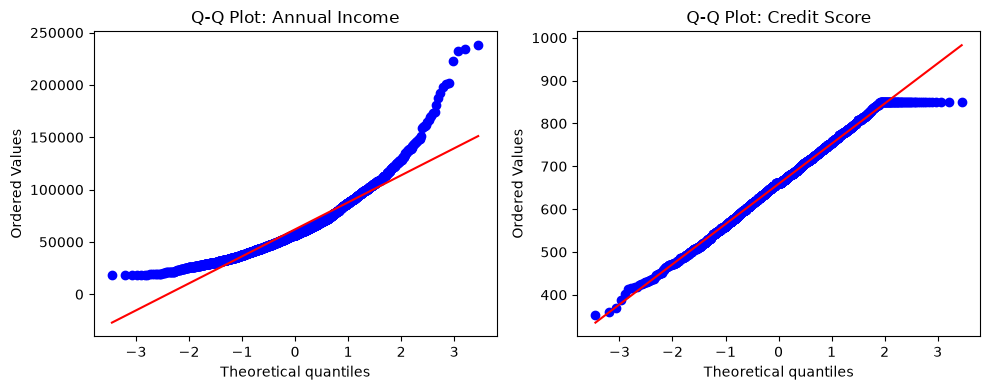

In [14]:
# ----- CELL 11 : STEP 4f - TESTING FOR NORMALITY -----
print("Shapiro-Wilk test   (H0: the variable is normally distributed)")
print("-" * 62)
for col in numeric_cols:
    statistic, p_value = stats.shapiro(df[col])
    verdict = "NOT normal" if p_value < 0.05 else "Normal"
    print(f"{col:<24} W={statistic:.4f}  p={p_value:.3g}  -> {verdict}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
stats.probplot(df['Annual_Income_USD'], dist="norm", plot=plt)
plt.title('Q-Q Plot: Annual Income')
plt.subplot(1, 2, 2)
stats.probplot(df['Credit_Score'], dist="norm", plot=plt)
plt.title('Q-Q Plot: Credit Score')
plt.tight_layout()
plt.show()

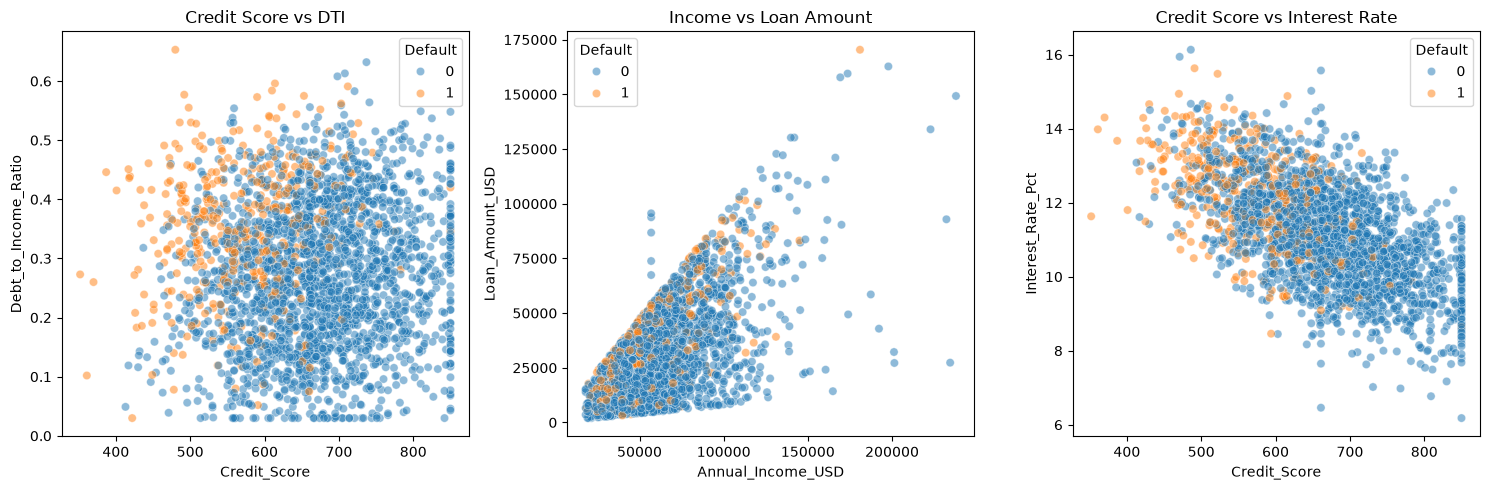

In [15]:
# ----- CELL 12 : STEP 4g - BIVARIATE: SCATTERPLOTS -----
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df, x='Credit_Score', y='Debt_to_Income_Ratio',
                hue='Default', alpha=0.5)
plt.title('Credit Score vs DTI')

plt.subplot(1, 3, 2)
sns.scatterplot(data=df, x='Annual_Income_USD', y='Loan_Amount_USD',
                hue='Default', alpha=0.5)
plt.title('Income vs Loan Amount')

plt.subplot(1, 3, 3)
sns.scatterplot(data=df, x='Credit_Score', y='Interest_Rate_Pct',
                hue='Default', alpha=0.5)
plt.title('Credit Score vs Interest Rate')

plt.tight_layout()
plt.show()

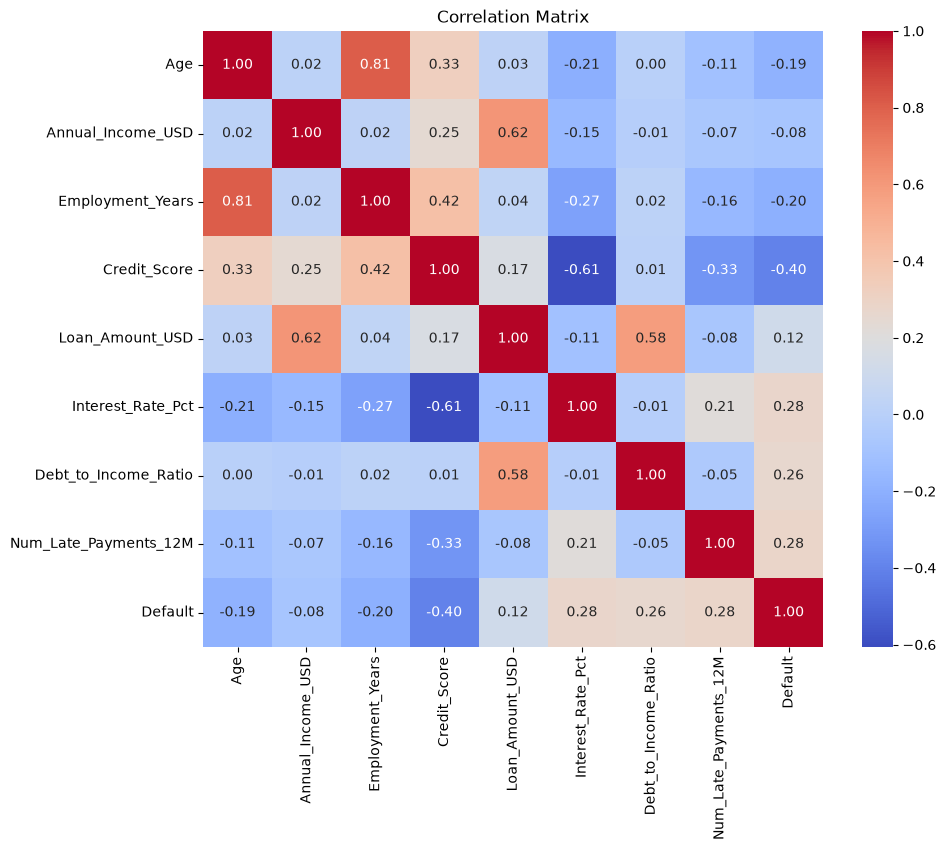

Default                  1.000
Num_Late_Payments_12M    0.280
Interest_Rate_Pct        0.278
Debt_to_Income_Ratio     0.262
Loan_Amount_USD          0.120
Annual_Income_USD       -0.084
Age                     -0.190
Employment_Years        -0.203
Credit_Score            -0.401
Name: Default, dtype: float64


In [16]:
# ----- CELL 13 : STEP 4h - BIVARIATE: CORRELATION HEATMAP -----
correlation_matrix = df[numeric_cols + ['Default']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

print(correlation_matrix['Default'].sort_values(ascending=False).round(3))

In [17]:
# ----- CELL 14 : STEP 3d - FEATURE ENCODING -----
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
print("Shape after encoding:", df.shape)
print(list(df.columns))

Shape after encoding: (2500, 20)
['Age', 'Annual_Income_USD', 'Employment_Years', 'Credit_Score', 'Loan_Amount_USD', 'Loan_Term_Months', 'Interest_Rate_Pct', 'Debt_to_Income_Ratio', 'Num_Late_Payments_12M', 'Default', 'Employment_Type_Salaried', 'Employment_Type_Self-Employed', 'Education_High School', 'Education_Post Graduate', 'Home_Ownership_Own', 'Home_Ownership_Rent', 'Loan_Purpose_Debt Consolidation', 'Loan_Purpose_Education', 'Loan_Purpose_Home Improvement', 'Loan_Purpose_Personal']


In [18]:
# ----- CELL 15 : STEP 5 - DEFINE X AND y -----
X = df.drop(columns=['Default'])
y = df['Default']
print("X shape:", X.shape, " y shape:", y.shape)

X shape: (2500, 19)  y shape: (2500,)


In [19]:
# ----- CELL 16 : STEP 6 - SPLIT INTO TRAINING AND TEST DATA -----
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)
print("Training rows:", X_train.shape[0], " Test rows:", X_test.shape[0])
print("Default rate in train: %.2f%%" % (100 * y_train.mean()))
print("Default rate in test : %.2f%%" % (100 * y_test.mean()))

Training rows: 2000  Test rows: 500
Default rate in train: 16.30%
Default rate in test : 16.40%


In [20]:
# ----- CELL 17 : STEP 6a - SCALING -----
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
print("Scaling done. Training mean ~0, sd ~1:")
print("  mean:", np.round(X_train_scaled.mean(), 4), " sd:", np.round(X_train_scaled.std(), 4))

Scaling done. Training mean ~0, sd ~1:
  mean: 0.0  sd: 1.0


In [21]:
# ----- CELL 18 : STEP 6b - HANDLING IMBALANCE WITH SMOTE -----
print("Before SMOTE:", np.bincount(y_train))

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print("After  SMOTE:", np.bincount(y_train_balanced))
print("Training rows went from", len(y_train), "to", len(y_train_balanced))

Before SMOTE: [1674  326]
After  SMOTE: [1674 1674]
Training rows went from 2000 to 3348


In [22]:
# ----- CELL 19 : STEP 7 - DEFINE THE MODEL -----
model = LogisticRegression(max_iter=1000, random_state=42)

In [23]:
# ----- CELL 20 : STEP 8 - FIT THE MODEL AND PRINT COEFFICIENTS -----
model.fit(X_train_balanced, y_train_balanced)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0],
    'Odds_Ratio': np.exp(model.coef_[0])
}).sort_values('Coefficient', key=abs, ascending=False)

print(coefficients.to_string(index=False))
print(f"\nIntercept: {model.intercept_[0]:.4f}")


                        Feature  Coefficient  Odds_Ratio
                   Credit_Score    -1.442810    0.236263
           Debt_to_Income_Ratio     1.015270    2.760110
                Loan_Amount_USD     0.644354    1.904756
          Num_Late_Payments_12M     0.614999    1.849654
              Annual_Income_USD    -0.574409    0.563038
               Employment_Years    -0.270660    0.762876
                            Age    -0.241583    0.785383
             Home_Ownership_Own    -0.209486    0.811001
              Interest_Rate_Pct     0.188376    1.207288
         Loan_Purpose_Education    -0.174109    0.840205
        Education_Post Graduate    -0.170071    0.843605
       Employment_Type_Salaried    -0.124591    0.882858
            Home_Ownership_Rent     0.083682    1.087283
          Loan_Purpose_Personal     0.081175    1.084560
  Loan_Purpose_Home Improvement    -0.050174    0.951064
Loan_Purpose_Debt Consolidation     0.035165    1.035791
  Employment_Type_Self-Employed

TRAINING PERFORMANCE
Accuracy : 0.8163
Precision: 0.8070
Recall   : 0.8315

Confusion Matrix:
[[1341  333]
 [ 282 1392]]


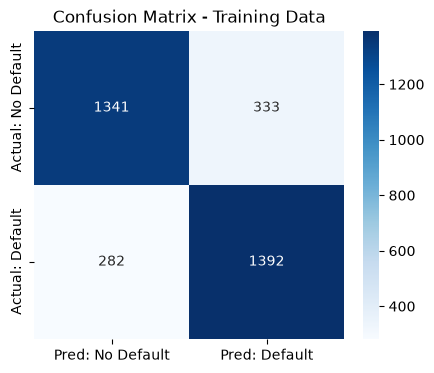

In [24]:
# ----- CELL 21 : STEP 9 - PREDICT ON TRAINING DATA AND SCORE -----
y_train_pred = model.predict(X_train_balanced)

print("TRAINING PERFORMANCE")
print(f"Accuracy : {accuracy_score(y_train_balanced, y_train_pred):.4f}")
print(f"Precision: {precision_score(y_train_balanced, y_train_pred):.4f}")
print(f"Recall   : {recall_score(y_train_balanced, y_train_pred):.4f}")

cm_train = confusion_matrix(y_train_balanced, y_train_pred)
print("\nConfusion Matrix:")
print(cm_train)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred: No Default', 'Pred: Default'],
            yticklabels=['Actual: No Default', 'Actual: Default'])
plt.title('Confusion Matrix - Training Data')
plt.show()

TEST PERFORMANCE
Accuracy : 0.8020
Precision: 0.4388
Recall   : 0.7439

Confusion Matrix:
[[340  78]
 [ 21  61]]


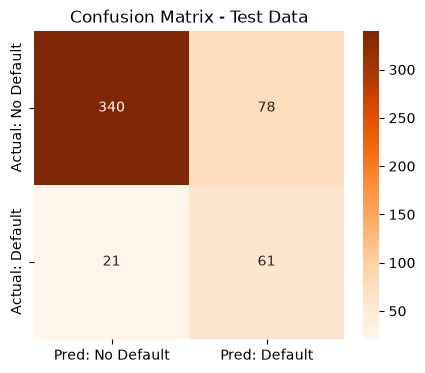


Full report:
              precision    recall  f1-score   support

  No Default       0.94      0.81      0.87       418
     Default       0.44      0.74      0.55        82

    accuracy                           0.80       500
   macro avg       0.69      0.78      0.71       500
weighted avg       0.86      0.80      0.82       500



In [25]:
# ----- CELL 22 : STEP 10 - PREDICT ON TEST DATA AND SCORE -----
y_test_pred = model.predict(X_test_scaled)

print("TEST PERFORMANCE")
print(f"Accuracy : {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_test_pred):.4f}")

cm_test = confusion_matrix(y_test, y_test_pred)
print("\nConfusion Matrix:")
print(cm_test)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Pred: No Default', 'Pred: Default'],
            yticklabels=['Actual: No Default', 'Actual: Default'])
plt.title('Confusion Matrix - Test Data')
plt.show()

print("\nFull report:")
print(classification_report(y_test, y_test_pred,
                            target_names=['No Default', 'Default']))

In [26]:
# ----- CELL 23 : STEP 11 - PROBABILITY OF DEFAULT CALCULATOR -----
def predict_default_probability(age, annual_income, employment_years, credit_score,
                                loan_amount, loan_term, interest_rate, dti,
                                late_payments, employment_type, education,
                                home_ownership, loan_purpose):

    row = pd.DataFrame(0, index=[0], columns=X.columns)

    row['Age']                   = age
    row['Annual_Income_USD']     = annual_income
    row['Employment_Years']      = employment_years
    row['Credit_Score']          = credit_score
    row['Loan_Amount_USD']       = loan_amount
    row['Loan_Term_Months']      = loan_term
    row['Interest_Rate_Pct']     = interest_rate
    row['Debt_to_Income_Ratio']  = dti
    row['Num_Late_Payments_12M'] = late_payments

    for prefix, value in [('Employment_Type', employment_type),
                          ('Education', education),
                          ('Home_Ownership', home_ownership),
                          ('Loan_Purpose', loan_purpose)]:
        dummy = prefix + '_' + value
        if dummy in row.columns:
            row[dummy] = 1

    row_scaled = scaler.transform(row)
    probability = model.predict_proba(row_scaled)[0][1]
    return probability


applicant_1 = predict_default_probability(
    age=42, annual_income=85000, employment_years=12, credit_score=720,
    loan_amount=25000, loan_term=36, interest_rate=9.0, dti=0.22,
    late_payments=0, employment_type='Salaried', education='Graduate',
    home_ownership='Mortgage', loan_purpose='Home Improvement')

applicant_2 = predict_default_probability(
    age=35, annual_income=65000, employment_years=8, credit_score=670,
    loan_amount=30000, loan_term=36, interest_rate=11.0, dti=0.30,
    late_payments=1, employment_type='Salaried', education='Graduate',
    home_ownership='Mortgage', loan_purpose='Personal')

applicant_3 = predict_default_probability(
    age=31, annual_income=52000, employment_years=4, credit_score=640,
    loan_amount=28000, loan_term=48, interest_rate=12.5, dti=0.38,
    late_payments=1, employment_type='Contract', education='Graduate',
    home_ownership='Rent', loan_purpose='Personal')

print(f"Applicant 1 (strong profile)     : {applicant_1:.2%}")
print(f"Applicant 2 (average profile)    : {applicant_2:.2%}")
print(f"Applicant 3 (borderline profile) : {applicant_3:.2%}")


Applicant 1 (strong profile)     : 0.95%
Applicant 2 (average profile)    : 25.96%
Applicant 3 (borderline profile) : 76.69%


In [27]:
# ----- CELL 24 : INTERACTIVE CALCULATOR (run this cell on its own) -----
print("Employment Type : Salaried / Self-Employed / Contract")
print("Education       : High School / Graduate / Post Graduate")
print("Home Ownership  : Own / Mortgage / Rent")
print("Loan Purpose    : Debt Consolidation / Home Improvement / Education / Business / Personal")

while True:
    if input("\nDo you want to predict default probability? (y/n): ").strip().lower() != 'y':
        break

    try:
        print("\n" + "=" * 45)
        print("PROBABILITY OF DEFAULT CALCULATOR")
        print("=" * 45)

        age           = float(input("Age (21-65)                     : "))
        annual_income = float(input("Annual Income USD (18k-250k)    : "))
        emp_years     = float(input("Employment Years (0-40)         : "))
        credit_score  = float(input("Credit Score (300-850)          : "))
        loan_amount   = float(input("Loan Amount USD (2k-180k)       : "))
        loan_term     = float(input("Loan Term Months (12/24/36/48/60): "))
        interest_rate = float(input("Interest Rate Pct (5-24)        : "))
        dti           = float(input("Debt to Income Ratio (0.03-0.72): "))
        late_payments = float(input("Late Payments in 12M (0-9)      : "))
        emp_type      = input("Employment Type                 : ").strip()
        education     = input("Education                       : ").strip()
        home          = input("Home Ownership                  : ").strip()
        purpose       = input("Loan Purpose                    : ").strip()

        prob = predict_default_probability(age, annual_income, emp_years, credit_score,
                                           loan_amount, loan_term, interest_rate, dti,
                                           late_payments, emp_type, education,
                                           home, purpose)

        if prob < 0.20:
            band, decision = "LOW RISK", "Approve"
        elif prob < 0.50:
            band, decision = "MEDIUM RISK", "Approve with conditions"
        else:
            band, decision = "HIGH RISK", "Decline or require collateral"

        print("\n" + "-" * 45)
        print(f"Probability of Default : {prob:.2%}")
        print(f"Risk Band              : {band}")
        print(f"Indicative Decision    : {decision}")
        print("-" * 45)

    except ValueError:
        print("Please enter valid numbers for the numeric fields.")

Employment Type : Salaried / Self-Employed / Contract
Education       : High School / Graduate / Post Graduate
Home Ownership  : Own / Mortgage / Rent
Loan Purpose    : Debt Consolidation / Home Improvement / Education / Business / Personal
